# Лабораторная работа №2. Виртуальный датчик для контроля обжига

Задача - оценить концентрацию продукта в момент $t$ по минутной телеметрии, доступной к этому моменту. Модель обучается на лабораторных пробах, а после обучения выдаёт оценку каждую минуту. Качество можно проверить только в моменты, для которых есть лабораторные значения.

In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.tsa.stattools import acf

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 20)
SEED = 42
DELAY = 12
MAX_DELAY = pd.Timedelta(minutes=15)
DATA = Path("data")

## 1. EDA и синхронизация

В файлах с целью есть только `Дата` и `target`. Я считаю, что в основном сценарии `Дата` - время выдачи результата, и сдвигаю её на 12 минут назад. Тогда значение концентрации относится к пробе в $t$, а телеметрия позже $t$ недоступна. В чувствительности проверю 10 и 15 минут, а также 0 минут на случай, если поле обозначает сам отбор. При этом для ориентира «последний анализ» считаю, что проба становится доступна через 15 минут после отбора.

In [2]:
def read_source(filename, time_column):
    return pd.read_csv(DATA / filename, parse_dates=[time_column], index_col=time_column).sort_index()


raw_train = read_source("data_train.csv", "datetime")
raw_test = read_source("data_test_small.csv", "datetime")
lab_train = read_source("target_train.csv", "Дата")["target"].dropna()
lab_test = read_source("target_test_small.csv", "Дата")["target"].dropna()
assert raw_train.index.max() < raw_test.index.min()
assert lab_train.index.is_unique and lab_test.index.is_unique
assert lab_train.index.max() < lab_test.index.min()

# Среднее в пределах одной минуты объединяет строки, если выгрузка разбила каналы.
def minute_grid(frame):
    assert (frame.index == frame.index.floor("min")).all()
    return frame.groupby(level=0).mean().asfreq("min")


train = minute_grid(raw_train)
test = minute_grid(raw_test)
summary = []
for name, raw, grid, lab in [("Train", raw_train, train, lab_train), ("Test", raw_test, test, lab_test)]:
    gaps = lab.index.to_series().diff().dt.total_seconds() / 60
    summary.append({
        "Часть": name, "Начало": grid.index.min(), "Конец": grid.index.max(),
        "Строки": len(raw), "Повторные метки": raw.index.duplicated().sum(),
        "Отсутствующие минуты": len(grid) - raw.index.nunique(),
        "Проб": len(lab), "Шаг проб, медиана (мин)": gaps.median(),
        "Шаг проб, максимум (мин)": gaps.max(),
        "Доля 120-мин. шагов": gaps.dropna().eq(120).mean(),
        "Средняя цель": lab.mean()
    })
summary_table = pd.DataFrame(summary).set_index("Часть")
display(summary_table.round({"Доля 120-мин. шагов": 3, "Средняя цель": 3}))
coverage = train.notna().mean()
channels = coverage[coverage >= .90].index.tolist()
missing = pd.DataFrame({"Train, %": 100 * train.isna().mean(), "Test, %": 100 * test.isna().mean()})
display(missing.round(3))

,Начало,Конец,Строки,Повторные метки,Отсутствующие минуты,Проб,"Шаг проб, медиана (мин)","Шаг проб, максимум (мин)",Доля 120-мин. шагов,Средняя цель
Часть,,,,,,,,,,
Train,2019-03-01 00:01:00,2019-10-07 19:58:00,319546,1548,0,1773,120.0,26430.0,0.886,0.254
Test,2019-10-07 19:59:00,2019-11-04 10:25:00,39943,196,0,318,120.0,1080.0,0.994,0.210


,"Train, %","Test, %"
telemetry_0,0.005,0.003
telemetry_1,0.005,0.003
telemetry_2,0.005,0.003
telemetry_3,0.005,0.003
telemetry_4,0.042,0.003
telemetry_5,0.005,0.003
telemetry_6,0.005,0.003
telemetry_7,0.005,0.003
telemetry_8,0.005,0.003
telemetry_9,0.005,0.003


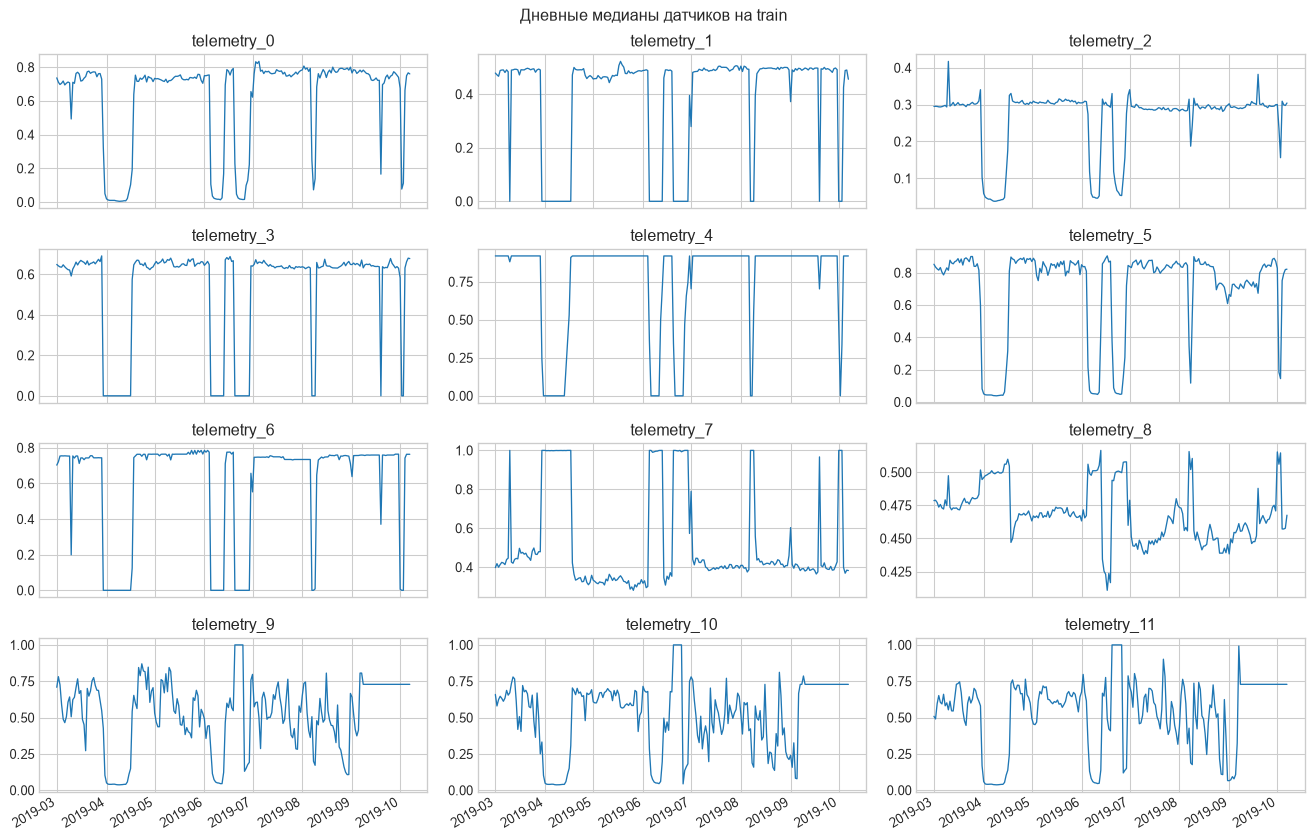

,% за пределами 3 IQR
telemetry_1,21.42
telemetry_4,21.38
telemetry_6,21.28
telemetry_7,20.87
telemetry_0,20.28
telemetry_3,19.85
telemetry_2,19.32
telemetry_5,15.94
telemetry_8,0.07
telemetry_9,0.00


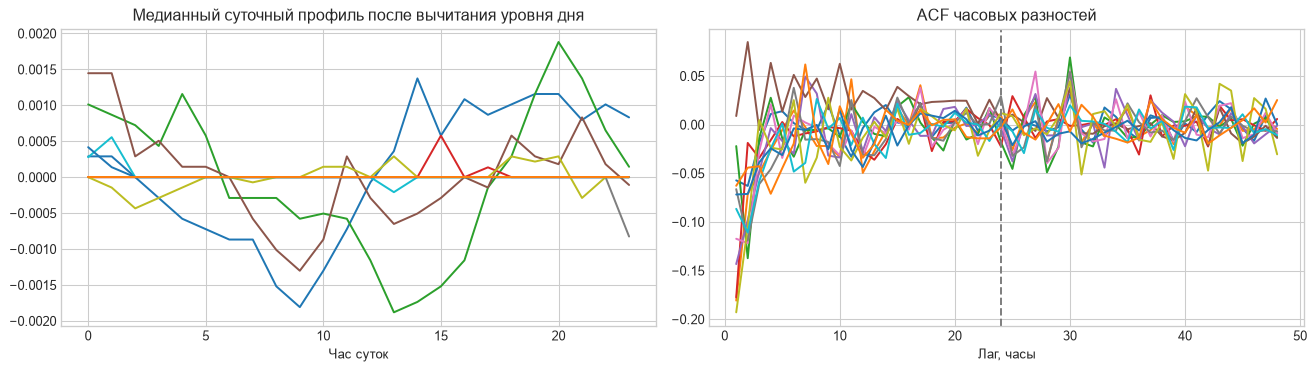

,24,48
telemetry_0,0.007,-0.009
telemetry_1,0.010,-0.004
telemetry_2,-0.018,-0.013
telemetry_3,-0.022,0.006
telemetry_4,-0.004,-0.001
telemetry_5,0.003,-0.014
telemetry_6,0.002,-0.009
telemetry_7,0.029,-0.007
telemetry_8,0.012,-0.031
telemetry_9,0.003,-0.011


In [3]:
# Дневные медианы показывают смену режима, а IQR служит только для разметки хвостов.
daily = train[channels].resample("1D").median()
fig, axes = plt.subplots(4, 3, figsize=(14, 9), sharex=True)
for col, ax in zip(channels, axes.flat):
    ax.plot(daily[col], linewidth=1)
    ax.set_title(col)
fig.suptitle("Дневные медианы датчиков на train")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

q1, q3 = train[channels].quantile([.25, .75]).to_numpy()
iqr = q3 - q1
tails = ((train[channels] < q1 - 3 * iqr) | (train[channels] > q3 + 3 * iqr))
display((100 * tails.mean()).sort_values(ascending=False).rename("% за пределами 3 IQR").round(2).to_frame())

# Для суточного профиля вычитаю дневной уровень, чтобы не принять дрейф за сезонность.
hourly = train[channels].resample("1h").median()
within_day = hourly - hourly.groupby(hourly.index.normalize()).transform("median")
profile = within_day.groupby(within_day.index.hour).median()
hourly_acf = pd.DataFrame({
    col: acf(hourly[col].diff().dropna(), nlags=48, fft=True) for col in channels
})
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
profile.plot(ax=axes[0], legend=False, title="Медианный суточный профиль после вычитания уровня дня")
hourly_acf.iloc[1:].plot(ax=axes[1], legend=False, title="ACF часовых разностей")
axes[1].axvline(24, color="grey", linestyle="--")
axes[1].set_xlabel("Лаг, часы")
axes[0].set_xlabel("Час суток")
plt.tight_layout()
plt.show()
display(hourly_acf.loc[[24, 48]].T.round(3))

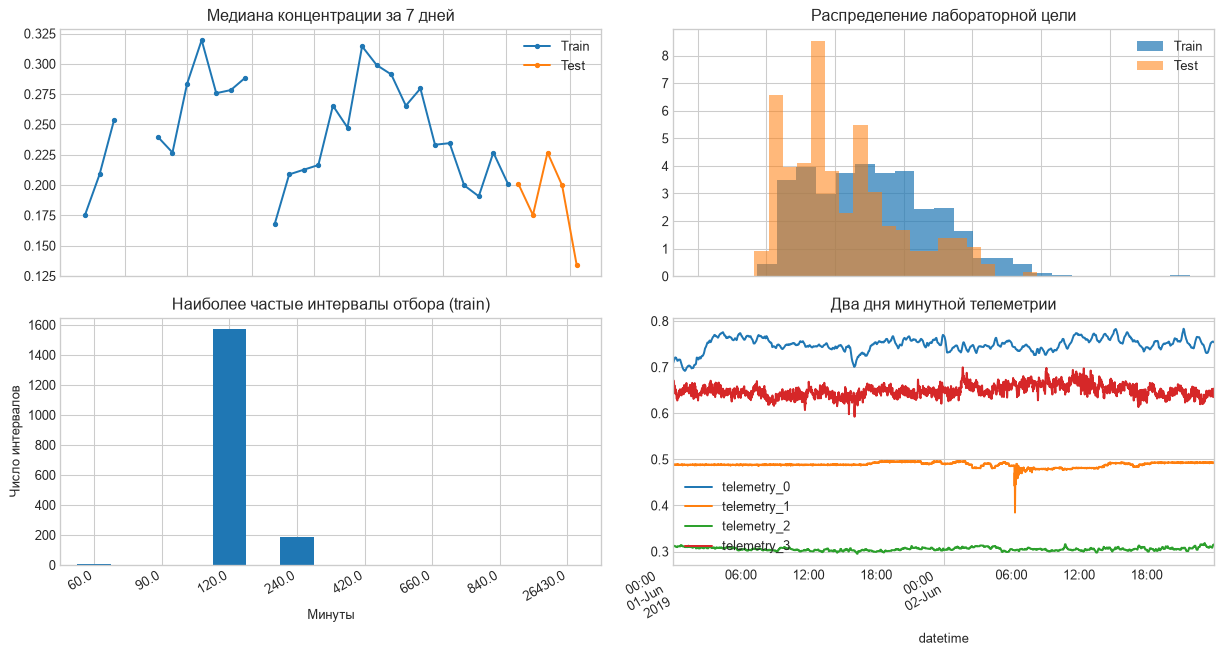

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
axes[0, 0].plot(lab_train.resample("7D").median(), marker=".", label="Train")
axes[0, 0].plot(lab_test.resample("7D").median(), marker=".", label="Test")
axes[0, 0].set_title("Медиана концентрации за 7 дней")
axes[0, 0].legend()
axes[0, 1].hist(lab_train, bins=25, alpha=.7, density=True, label="Train")
axes[0, 1].hist(lab_test, bins=20, alpha=.55, density=True, label="Test")
axes[0, 1].set_title("Распределение лабораторной цели")
axes[0, 1].legend()
lab_train.index.to_series().diff().dt.total_seconds().div(60).value_counts().head(8).sort_index().plot.bar(ax=axes[1, 0])
axes[1, 0].set(title="Наиболее частые интервалы отбора (train)", xlabel="Минуты", ylabel="Число интервалов")
train.loc["2019-06-01":"2019-06-02", channels[:4]].plot(ax=axes[1, 1], title="Два дня минутной телеметрии")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Сопоставлено проб: 1772 train и 318 test
Вне телеметрии своего периода: 1 0


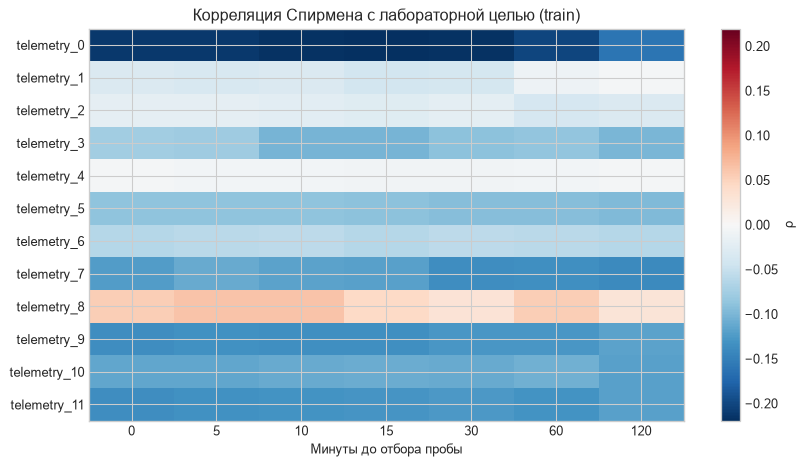

,0,5,10,15,30,60,120
telemetry_0,-0.212,-0.211,-0.217,-0.220,-0.218,-0.201,-0.160
telemetry_1,-0.032,-0.035,-0.032,-0.041,-0.038,-0.011,-0.004
telemetry_2,-0.020,-0.020,-0.023,-0.027,-0.021,-0.037,-0.031
telemetry_3,-0.077,-0.078,-0.101,-0.103,-0.090,-0.087,-0.100
telemetry_4,-0.005,-0.006,-0.007,-0.008,-0.007,-0.006,-0.005
telemetry_5,-0.089,-0.089,-0.088,-0.089,-0.093,-0.093,-0.097
telemetry_6,-0.063,-0.059,-0.057,-0.063,-0.058,-0.059,-0.062
telemetry_7,-0.122,-0.110,-0.117,-0.119,-0.136,-0.135,-0.140
telemetry_8,0.053,0.063,0.063,0.044,0.030,0.054,0.028
telemetry_9,-0.136,-0.133,-0.135,-0.135,-0.128,-0.128,-0.117


In [5]:
def sample_times(lab, delay):
    shifted = lab.copy()
    shifted.index = lab.index - pd.Timedelta(minutes=delay)
    return shifted.rename("target")


def inside_grid(lab, grid):
    return lab.loc[(lab.index >= grid.index.min()) & (lab.index <= grid.index.max())]


aligned_train = inside_grid(sample_times(lab_train, DELAY), train)
aligned_test = inside_grid(sample_times(lab_test, DELAY), test)
print("Сопоставлено проб:", len(aligned_train), "train и", len(aligned_test), "test")
print("Вне телеметрии своего периода:", len(lab_train) - len(aligned_train), len(lab_test) - len(aligned_test))

# Лаг k берёт датчик в t-k. Корреляции считаю на train по рангу, без будущих точек.
lag_corr = {}
for lag in [0, 5, 10, 15, 30, 60, 120]:
    values = train[channels].shift(lag).reindex(aligned_train.index)
    lag_corr[lag] = values.corrwith(aligned_train, method="spearman")

correlations = pd.DataFrame(lag_corr)
fig, ax = plt.subplots(figsize=(9, 5))
limit = correlations.abs().max().max()
plot = ax.imshow(correlations, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(len(correlations.columns)), correlations.columns)
ax.set_yticks(range(len(channels)), channels)
ax.set(xlabel="Минуты до отбора пробы", title="Корреляция Спирмена с лабораторной целью (train)")
fig.colorbar(plot, ax=ax, label="ρ")
plt.tight_layout()
plt.show()
display(correlations.round(3))

### Вывод 1. Данные и привязка проб

После объединения повторов пропущенных минут нет. Из 16 каналов я оставил 12, по которым регулярно приходят значения. Пробы обычно берут раз в два часа, хотя иногда паузы длиннее. При сдвиге на 12 минут к телеметрии удалось привязать 1 772 обучающие и все 318 тестовых проб. На тесте среднее значение концентрации ниже (0,210 против 0,254).

Самая заметная связь с концентрацией получилась у `telemetry_0` за 15 минут до пробы (корреляция Спирмена -0,220). На суточном лаге автокорреляция часовых разностей слабая, поэтому календарные признаки я не добавлял. Крайние значения сохранил: без описания датчиков трудно понять, где сбой, а где реальная смена режима.

## 2. Признаки по минутной истории

Беру текущий уровень, лаги 5/15/30/60 минут, статистики за 15 и 60 минут и скорость изменения за 5/15 минут. Среднее показывает уровень режима, std - его стабильность, min/max - диапазон. Разность в единицу времени сохраняет масштаб датчика и устойчива к значениям около нуля, где процентный рост становится нестабильным.

Короткие пропуски закрываю предыдущим значением максимум на 3 минуты. Для окон нужно минимум 80% заполненных минут. Оставшиеся NaN линейная модель и лес заполняют медианами обучающей части, бустинг обрабатывает их внутри деревьев. Четыре разреженных канала исключаю по покрытию train. Источник и доступность этих каналов в реальном времени неизвестны.

In [6]:
LAGS = [5, 15, 30, 60]
WINDOWS = [15, 60]


def make_features(frame):
    values = frame[channels].astype("float32").ffill(limit=3)
    parts = [values]
    for lag in LAGS:
        parts.append(values.shift(lag).add_suffix(f"_lag{lag}"))
    for size in WINDOWS:
        window = values.rolling(size, min_periods=int(size * .8))
        for stat in ["mean", "std", "min", "max"]:
            parts.append(getattr(window, stat)().astype("float32").add_suffix(f"_{stat}{size}"))
    for lag in [5, 15]:
        parts.append((values.diff(lag) / lag).add_suffix(f"_rate{lag}"))
    return pd.concat(parts, axis=1)


# Беру хвост train для прогрева окон теста. Статистики используют только прошлое и текущую минуту.
features_train = make_features(train)
history = pd.concat([train.tail(64), test])
assert history.index.to_series().diff().dropna().eq(pd.Timedelta(minutes=1)).all()
features_test = make_features(history).loc[test.index]
X = features_train.reindex(aligned_train.index)
y = aligned_train
X_test = features_test.reindex(aligned_test.index)
y_test = aligned_test

# Сверяю строку из полного расчёта с расчётом на истории, оборванной в момент пробы.
t = X.index[len(X) // 2]
prefix = make_features(train.loc[:t].tail(65)).iloc[-1]
np.testing.assert_allclose(prefix, X.loc[t], rtol=1e-4, atol=1e-7, equal_nan=True)
print(f"Признаков: {X.shape[1]}. Доля пустых ячеек train: {X.isna().mean().mean():.3%}")
display(X.iloc[:3, :6])

Признаков: 180. Доля пустых ячеек train: 0.005%


,telemetry_0,telemetry_1,telemetry_2,telemetry_3,telemetry_4,telemetry_5
Дата,,,,,,
2019-03-13 16:48:00,0.787305,0.502351,0.308730,0.651176,0.919471,0.879027
2019-03-13 20:48:00,0.782386,0.497251,0.301207,0.655321,0.919471,0.856169
2019-03-14 00:48:00,0.787305,0.497028,0.300339,0.633237,0.919471,0.876712


### Вывод 2. Признаки

Из 12 каналов получилось 180 признаков. По ним модель видит, как менялись показания за последний час и насколько сильно они колебались. PCA я не применял, чтобы потом можно было разобрать вклад каждого датчика. В Ridge похожие признаки учитываются с помощью регуляризации.

## 3. Модели и проверка на train

- **Ridge** - линейная модель со штрафом за большие коэффициенты. Даёт быстрый ориентир для проверки того, сколько объясняют уровни и лаги.
- **Случайный лес** - усредняет независимые деревья и может описать взаимодействия каналов в разных режимах. Ограничение глубины и размера листа уменьшает подгонку к отдельным пробам.
- **Градиентный бустинг** - последовательно исправляет ошибки деревьев. Ограничиваю число листьев и использую регуляризацию. Встроенную раннюю остановку отключаю, чтобы внутри обучения не появилось случайное разбиение.
- **Две OLS-регрессии** - компактный статистический ориентир для AIC/BIC. Первая использует уровни датчиков, вторая добавляет 15-минутные средние и скорости изменения.

Обычные ETS и одномерная ARIMA по лабораторным значениям не подходят в исходном виде: пробы редкие и нерегулярные, а модели нужно выдавать оценку каждую минуту по свежей телеметрии. Стандартный VAR также требует совместно наблюдаемых рядов на общей сетке. Заполнение цели между пробами искусственно создаст метки, которых лаборатория не измеряла. TimeLLM из практики решает другую задачу: прогноз будущих значений регулярного ряда. Для его адаптации здесь понадобились бы новые входы и схема обучения с редкими метками. При примерно 1,8 тыс. проб сложную сеть с нуля трудно обосновать.

Параметры выбираю по среднему MAE трёх временных фолдов. Перед началом валидации оставляю 75 минут, чтобы разделить часовые окна и учесть доступность анализа с задержкой до 15 минут.

In [7]:
def temporal_folds(index):
    for fit_rows, val_rows in TimeSeriesSplit(n_splits=3).split(index):
        cutoff = index[val_rows[0]] - pd.Timedelta(minutes=75)
        fit_rows = fit_rows[index[fit_rows] < cutoff]
        yield fit_rows, val_rows


def ridge(alpha):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha))


def forest(depth):
    return make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(n_estimators=120, max_depth=depth, min_samples_leaf=8,
                              max_features=.55, random_state=SEED, n_jobs=1)
    )


def boost(leaves):
    return HistGradientBoostingRegressor(max_iter=120, learning_rate=.05, max_leaf_nodes=leaves,
                                        min_samples_leaf=20, l2_regularization=.2,
                                        early_stopping=False, random_state=SEED)


candidates = {
    "Ridge": {10: ridge(10), 100: ridge(100), 400: ridge(400)},
    "Лес": {5: forest(5), 9: forest(9)},
    "Бустинг": {7: boost(7), 15: boost(15)}
}


def validate(model, x, target):
    scores = []
    for fit, val in temporal_folds(x.index):
        prediction = clone(model).fit(x.iloc[fit], target.iloc[fit]).predict(x.iloc[val])
        scores.append(np.mean(np.abs(target.iloc[val] - prediction)))
    return scores


rows = []
for family, options in candidates.items():
    for value, model in options.items():
        scores = validate(model, X, y)
        rows.append([family, value, *scores, np.mean(scores)])
cv = pd.DataFrame(rows, columns=["Модель", "Параметр", "Фолд 1", "Фолд 2", "Фолд 3", "CV MAE"])
cv = cv.sort_values("CV MAE")
best = cv.drop_duplicates("Модель").set_index("Модель")
winner = cv.iloc[0]["Модель"]
display(cv.round(5))
display(pd.DataFrame([
    {"Train до": X.index[fit[-1]], "Val с": X.index[val[0]], "Val до": X.index[val[-1]],
     "Train": len(fit), "Val": len(val)}
    for fit, val in temporal_folds(X.index)
]))

,Модель,Параметр,Фолд 1,Фолд 2,Фолд 3,CV MAE
5,Бустинг,7,0.07579,0.07574,0.06566,0.07240
2,Ridge,400,0.07639,0.07176,0.07021,0.07279
4,Лес,9,0.07490,0.07734,0.06685,0.07303
3,Лес,5,0.07481,0.07793,0.06746,0.07340
6,Бустинг,15,0.07747,0.07754,0.06658,0.07386
1,Ridge,100,0.08102,0.07291,0.07109,0.07501
0,Ridge,10,0.09146,0.07509,0.07374,0.08010


,Train до,Val с,Val до,Train,Val
0,2019-05-09 10:48:00,2019-05-09 12:48:00,2019-07-04 12:48:00,443,443
1,2019-07-04 12:48:00,2019-07-04 14:48:00,2019-08-16 12:48:00,886,443
2,2019-08-16 12:48:00,2019-08-16 14:48:00,2019-10-07 18:48:00,1329,443


In [8]:
# Сравниваю предположения о задержке на одинаковых исходных пробах, только в train.
last_common = train.index.max()
common_lab = lab_train.loc[(lab_train.index >= train.index.min() + MAX_DELAY) & (lab_train.index <= last_common)]
delay_scores = []
for delay in [0, 10, 12, 15]:
    labels = sample_times(common_lab, delay)
    scores = validate(ridge(100), features_train.reindex(labels.index), labels)
    delay_scores.append([delay, *scores, np.mean(scores)])
display(pd.DataFrame(delay_scores, columns=["Сдвиг, мин", "Фолд 1", "Фолд 2", "Фолд 3", "CV MAE"]).round(5))

ridge_alpha = best.loc["Ridge", "Параметр"]
current_mae = np.mean(validate(ridge(ridge_alpha), X[channels], y))
dynamic_mae = best.loc["Ridge", "CV MAE"]
display(pd.Series({"Текущие показания": current_mae, "Полный набор": dynamic_mae},
                  name="CV MAE для Ridge").round(5).to_frame())

,"Сдвиг, мин",Фолд 1,Фолд 2,Фолд 3,CV MAE
0,0,0.08008,0.07317,0.06821,0.07382
1,10,0.08166,0.07412,0.07308,0.07629
2,12,0.08102,0.07291,0.07109,0.07501
3,15,0.07768,0.07362,0.07134,0.07421


,CV MAE для Ridge
Текущие показания,0.07309
Полный набор,0.07279


### Вывод 3. Выбор модели

На временной валидации лучше всего выступил бустинг со средним MAE 0,0724. У Ridge добавление лагов и окон дало небольшое улучшение с 0,0731 до 0,0728. Оценки для разных сдвигов получились близкими. По ним нельзя установить реальное время отбора, поэтому для итогового сравнения я оставил исходное допущение в 12 минут.

## 4. Проверка на отложенном периоде

MAE и RMSE приведены в шкале исходного target. Для MAPE исключаю нулевые факты и показываю размер знаменателя выборки. WAPE - сумма абсолютных ошибок, делённая на сумму модулей фактов. Для направления беру знак разности соседних прогнозов и фактов с шагом ровно два часа. MDA считает долю совпадений на парах, где факт менялся. Сбалансированная точность направления усредняет полноту роста и падения.

In [9]:
models = {}
predictions = {}
timing = []


def measure_predict(model, x):
    model.predict(x)
    samples = []
    for _ in range(5):
        start = perf_counter()
        model.predict(x)
        samples.append(perf_counter() - start)
    return 1000 * np.median(samples) / len(x)


assert y.index.max() + MAX_DELAY < y_test.index.min()
for name, row in best.iterrows():
    model = clone(candidates[name][row["Параметр"]])
    start = perf_counter()
    model.fit(X, y)
    fit_seconds = perf_counter() - start
    models[name] = model
    predictions[name] = model.predict(X_test)
    timing.append([name, fit_seconds, measure_predict(model, X_test), measure_predict(model, X_test.iloc[:1])])

# Информационные критерии сравниваю у двух OLS с гауссовой ошибкой на одинаковых пробах.
ols_criteria = []
for name, cols in [
    ("OLS уровни", channels),
    ("OLS динамика", channels + [col + "_mean15" for col in channels]
                     + [col + "_rate15" for col in channels])
]:
    start = perf_counter()
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    fit_matrix = sm.add_constant(imputer.fit_transform(X[cols]), has_constant="add")
    result = sm.OLS(y.to_numpy(), fit_matrix).fit()
    fit_seconds = perf_counter() - start
    test_matrix = sm.add_constant(imputer.transform(X_test[cols]), has_constant="add")
    start = perf_counter()
    predictions[name] = result.predict(test_matrix)
    batch_ms = (perf_counter() - start) * 1000 / len(X_test)
    ols_criteria.append([name, int(result.nobs), int(result.df_model + 1), result.aic, result.bic])
    timing.append([name, fit_seconds, batch_ms, np.nan])

display(pd.DataFrame(ols_criteria, columns=["Модель", "n", "Ранг матрицы", "AIC", "BIC"]).round(2))
display(pd.DataFrame(timing, columns=["Модель", "Обучение, с", "Пакет, мс/строка", "1 строка, мс"]).round(5))

,Модель,n,Ранг матрицы,AIC,BIC
0,OLS уровни,1772,13,-3668.17,-3596.93
1,OLS динамика,1772,37,-3666.64,-3463.89


,Модель,"Обучение, с","Пакет, мс/строка","1 строка, мс"
0,Бустинг,0.20156,0.00439,1.11417
1,Ridge,0.01998,0.00354,0.87817
2,Лес,3.08219,0.01703,3.87067
3,OLS уровни,0.00662,0.00079,NaN
4,OLS динамика,0.00807,0.00003,NaN


Проб с доступным предыдущим анализом: 318


,MAE,RMSE,"MAPE, %","WAPE, %",MAPE n,"MDA, %","Balanced DA, %",Пар MDA
Последний анализ,0.0595,0.0801,29.7174,28.3682,318.0,35.1171,35.0784,299.0
Лес,0.0621,0.0768,34.2095,29.6051,318.0,57.5251,57.4552,299.0
Бустинг,0.0622,0.0770,34.4495,29.6771,318.0,53.5117,53.4857,299.0
Ridge,0.0650,0.0816,37.2694,31.0141,318.0,54.5151,54.5027,299.0
OLS динамика,0.0654,0.0805,37.6961,31.1754,318.0,59.5318,59.4892,299.0
OLS уровни,0.0659,0.0809,37.8893,31.4101,318.0,58.8629,58.6962,299.0
Медиана train,0.0768,0.0888,45.7627,36.6391,318.0,0.0000,0.0000,299.0


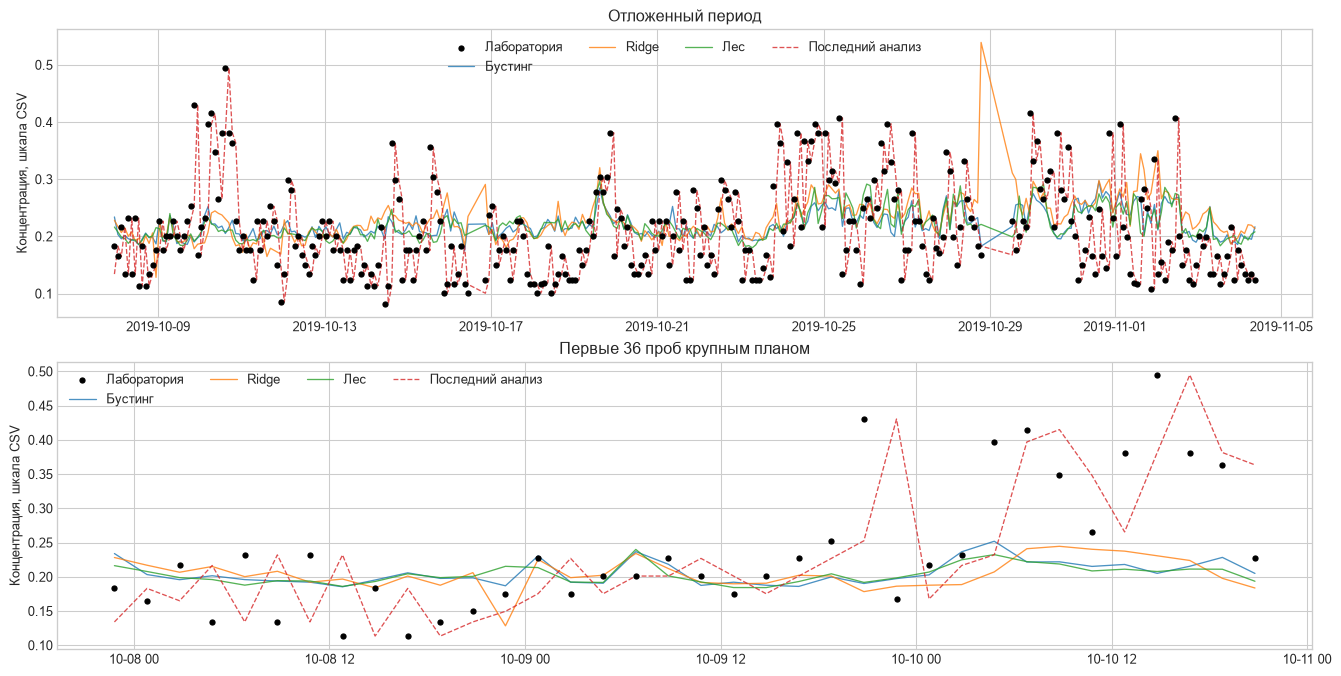

In [10]:
# Ориентиры для сравнения: медиана train и последний анализ, уже доступный оператору.
predictions["Медиана train"] = np.repeat(y.median(), len(y_test))
lab_history = pd.concat([sample_times(lab_train, DELAY), sample_times(lab_test, DELAY)])
lab_history.index += MAX_DELAY
previous_lab = lab_history.reindex(y_test.index, method="ffill")
predictions["Последний анализ"] = previous_lab.fillna(y.median()).to_numpy()
print("Проб с доступным предыдущим анализом:", previous_lab.notna().sum())


def score(target, prediction):
    actual = target.to_numpy()
    errors = actual - prediction
    nonzero = actual != 0
    dy = np.diff(actual)
    dp = np.diff(prediction)
    two_hours = np.diff(target.index.to_numpy()) == np.timedelta64(120, "m")
    directional = two_hours & (dy != 0)
    hit = np.sign(dy) == np.sign(dp)
    up = directional & (dy > 0)
    down = directional & (dy < 0)
    return {
        "MAE": np.abs(errors).mean(),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "MAPE, %": 100 * np.mean(np.abs(errors[nonzero] / actual[nonzero])) if nonzero.any() else np.nan,
        "WAPE, %": 100 * np.abs(errors).sum() / np.abs(actual).sum() if nonzero.any() else np.nan,
        "MAPE n": nonzero.sum(),
        "MDA, %": 100 * hit[directional].mean(),
        "Balanced DA, %": 50 * (hit[up].mean() + hit[down].mean()),
        "Пар MDA": directional.sum()
    }


metrics = pd.DataFrame({name: score(y_test, pred) for name, pred in predictions.items()}).T
metrics = metrics.sort_values("MAE")
display(metrics.round(4))

fig, axes = plt.subplots(2, 1, figsize=(14, 7), constrained_layout=True)
all_pred = pd.DataFrame(predictions, index=y_test.index)
for ax, dates in zip(axes, [y_test.index, y_test.index[:36]]):
    ax.scatter(dates, y_test.loc[dates], label="Лаборатория", s=14, color="black", zorder=4)
    for name in [*models, "Последний анализ"]:
        line = "--" if name == "Последний анализ" else "-"
        ax.plot(dates, all_pred.loc[dates, name], line, label=name, alpha=.8, linewidth=1)
    ax.set_ylabel("Концентрация, шкала CSV")
    ax.legend(ncol=4)
axes[0].set_title("Отложенный период")
axes[1].set_title("Первые 36 проб крупным планом")
plt.show()

### Вывод 4. Результаты на тесте

На 318 пробах у бустинга MAE составил 0,0622, RMSE - 0,0770, WAPE - 29,7%. Направление изменения он угадал в 53,5% из 299 пар. Случайный лес немного опередил бустинг по тестовому MAE (0,0621). Самый низкий MAE получился у последнего доступного лабораторного анализа (0,0595).

У OLS с текущими показаниями ниже и AIC, и BIC. В этой паре моделей улучшение подгонки оказалось слишком небольшим для добавленных признаков. Сравнение условно из-за предположения о независимых гауссовых ошибках. Время предсказания в таблице измерено на уже готовых признаках.

## 5. Остатки, важность признаков и минутная оценка

Jarque-Bera проверяет форму распределения остатков. Ljung-Box считаю на самой длинной серии проб с постоянным шагом 2 часа, чтобы лаги соответствовали времени. Для Breusch-Pagan объясняющей переменной служит уровень прогноза. Этот тест ищет изменение разброса ошибки вместе с уровнем, а его p-value при зависимости остатков следует считать ориентировочным.

Проб в регулярном блоке для Ljung–Box: 144


,Средняя ошибка,JB p,LB p (12 ч),BP p
Модель,,,,
Бустинг,-0.010695,0.000000,0.000000,0.001546
Ridge,-0.019567,0.000000,0.000000,0.000000
Лес,-0.010118,0.000000,0.000000,0.010929
OLS уровни,-0.023461,0.000004,0.000001,0.000000
OLS динамика,-0.023004,0.000018,0.000002,0.000000
Последний анализ,-0.000032,0.000013,0.002055,0.000008


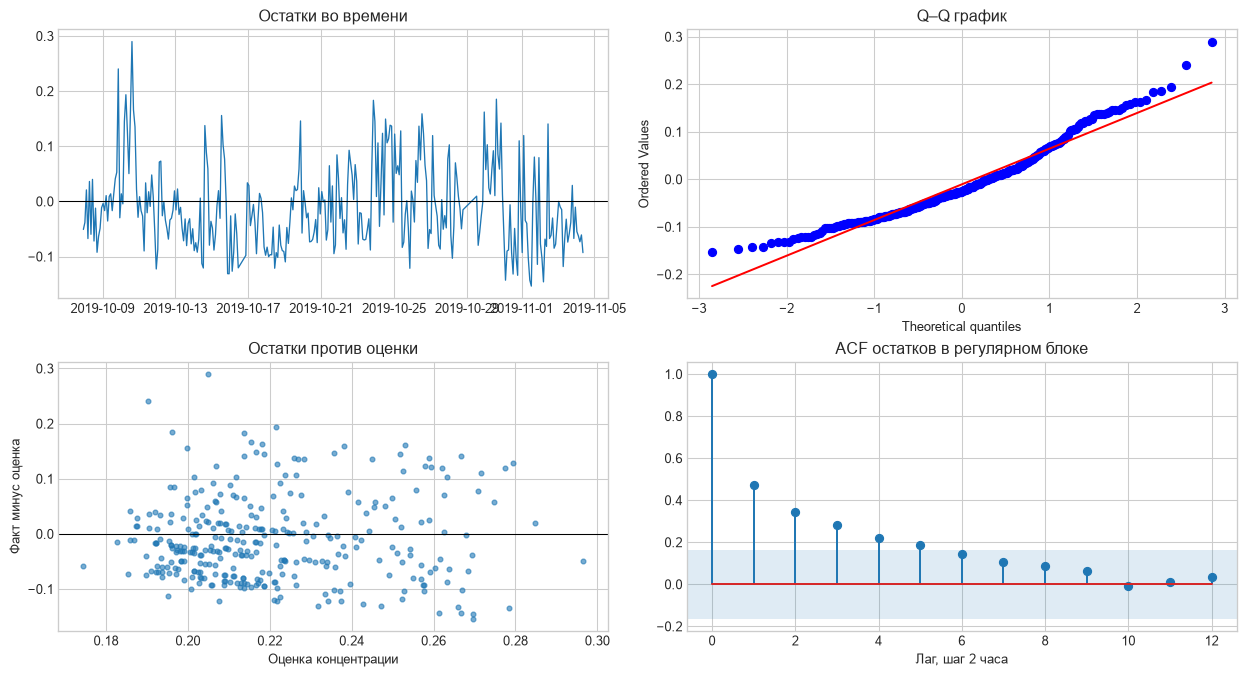

In [11]:
segments = y_test.index.to_series().diff().ne(pd.Timedelta(hours=2)).cumsum()
regular = segments.eq(segments.value_counts().idxmax()).to_numpy()
diagnostics = []
for name, pred in predictions.items():
    if name == "Медиана train":
        continue
    err = y_test.to_numpy() - pred
    lb = acorr_ljungbox(err[regular], lags=[6], return_df=True).iloc[0]["lb_pvalue"]
    bp = het_breuschpagan(err, sm.add_constant(pred))[1]
    diagnostics.append([name, err.mean(), stats.jarque_bera(err).pvalue, lb, bp])
diag = pd.DataFrame(diagnostics, columns=["Модель", "Средняя ошибка", "JB p", "LB p (12 ч)", "BP p"]).set_index("Модель")
print("Проб в регулярном блоке для Ljung–Box:", regular.sum())
display(diag.round(6))

err = y_test.to_numpy() - predictions[winner]
fig, axes = plt.subplots(2, 2, figsize=(13, 7), constrained_layout=True)
axes[0, 0].plot(y_test.index, err, linewidth=1)
axes[0, 0].axhline(0, color="black", linewidth=.8)
axes[0, 0].set_title("Остатки во времени")
stats.probplot(err, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Q–Q график")
axes[1, 0].scatter(predictions[winner], err, s=13, alpha=.6)
axes[1, 0].axhline(0, color="black", linewidth=.8)
axes[1, 0].set(xlabel="Оценка концентрации", ylabel="Факт минус оценка", title="Остатки против оценки")
axes[1, 1].stem(np.arange(13), acf(err[regular], nlags=12))
axes[1, 1].axhspan(-1.96 / np.sqrt(regular.sum()), 1.96 / np.sqrt(regular.sum()), alpha=.14)
axes[1, 1].set(title="ACF остатков в регулярном блоке", xlabel="Лаг, шаг 2 часа")
plt.show()

,Δ MAE,SD повторов
telemetry_0,0.00385,0.00146
telemetry_3,0.00141,0.00041
telemetry_6,0.00117,0.00037
telemetry_8,0.00027,0.00019
telemetry_2,0.00018,0.00056
telemetry_7,0.00006,0.00024
telemetry_9,0.00000,0.00000
telemetry_11,0.00000,0.00000
telemetry_10,-0.00000,0.00000
telemetry_4,-0.00010,0.00031


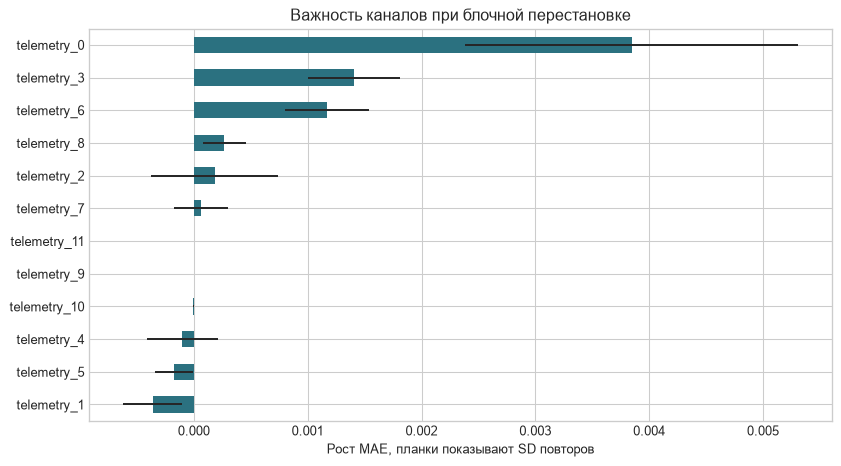

In [12]:
# Переставляю все признаки датчика вместе и блоками по 12 проб.
# Так сохраняется связь между лагами одного датчика и часть временной структуры.
model = models[winner]
rng = np.random.default_rng(SEED)
blocks = [np.arange(i, min(i + 12, len(X_test))) for i in range(0, len(X_test), 12)]
importance = {}
base = metrics.loc[winner, "MAE"]
for channel in channels:
    cols = [col for col in X_test if col == channel or col.startswith(channel + "_")]
    differences = []
    for _ in range(12):
        order = np.concatenate([blocks[i] for i in rng.permutation(len(blocks))])
        shuffled = X_test.copy()
        shuffled[cols] = X_test[cols].iloc[order].to_numpy()
        differences.append(np.mean(np.abs(y_test.to_numpy() - model.predict(shuffled))) - base)
    importance[channel] = (np.mean(differences), np.std(differences, ddof=1))

ranking = pd.DataFrame.from_dict(importance, orient="index", columns=["Δ MAE", "SD повторов"]).sort_values("Δ MAE")
display(ranking.sort_values("Δ MAE", ascending=False).round(5))
ranking["Δ MAE"].plot.barh(xerr=ranking["SD повторов"], figsize=(9, 5), color="#2b7180",
                          title="Важность каналов при блочной перестановке")
plt.xlabel("Рост MAE, планки показывают SD повторов")
plt.tight_layout()
plt.show()

Доступность минутной оценки в тестовом периоде: 100.00%


,Концентрация
datetime,
2019-10-07 19:59:00,0.228326
2019-10-07 20:00:00,0.237671
2019-10-07 20:01:00,0.237207
2019-10-07 20:02:00,0.242207
2019-10-07 20:03:00,0.239905


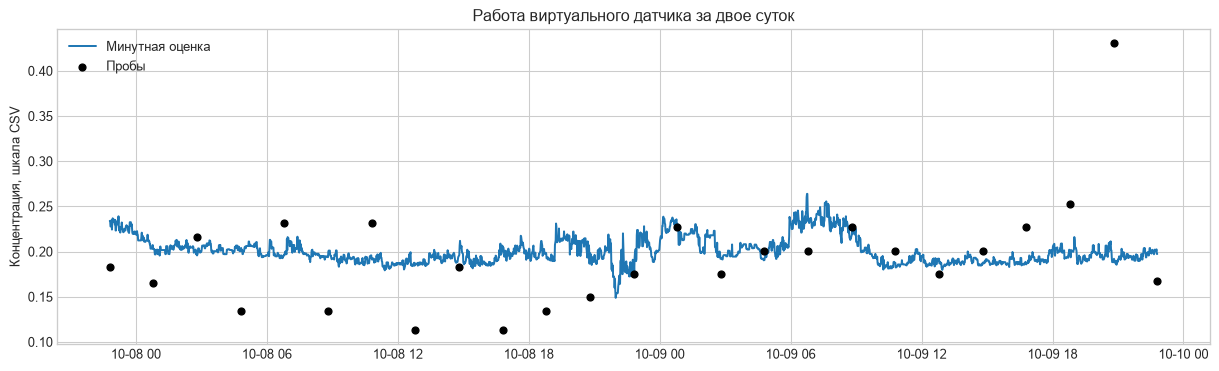

In [13]:
# Считаю оценку на всей минутной сетке. При слабом покрытии входа результат скрываю.
usable = features_test[channels].notna().mean(axis=1).ge(.8)
minute_prediction = pd.Series(np.nan, index=features_test.index, name="Концентрация")
minute_prediction.loc[usable] = model.predict(features_test.loc[usable])
display(minute_prediction.head().to_frame())
print(f"Доступность минутной оценки в тестовом периоде: {usable.mean():.2%}")

start = y_test.index[0]
end = start + pd.Timedelta(hours=48)
window = minute_prediction.loc[start:end]
lab_window = y_test.loc[start:end]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(window, label="Минутная оценка")
ax.scatter(lab_window.index, lab_window, s=27, color="black", label="Пробы", zorder=3)
ax.set(title="Работа виртуального датчика за двое суток", ylabel="Концентрация, шкала CSV")
ax.legend()
plt.tight_layout()
plt.show()

### Вывод 5. Остатки и работа виртуального датчика

По трём тестам для бустинга получились p-value меньше 0,05. Остатки отличаются от нормального распределения, связаны во времени, а их разброс зависит от уровня оценки. В среднем модель завышает концентрацию примерно на 0,011 в шкале исходного столбца `target`.

При перестановке сильнее всего росла ошибка у `telemetry_0`, `telemetry_3` и `telemetry_6`. Возможно, история этих каналов помогает учитывать инерцию печи. Показания обезличены, поэтому связать конкретный канал с температурой или подачей сырья можно только по карте датчиков. Важность показывает, насколько модель опирается на канал.

На тестовом отрезке данных хватило для оценки в каждую минуту. Проверить её точность можно только в моменты проб. Перед применением для сигналов оператору я бы уточнил, что именно означает лабораторная метка, и проверил ошибки на новых режимах.